# [WEEK 7] A/B Test Design — Assignment (학생용)

**과제 유형: B. 도구 활용형** (생성형 AI 사용 가능, 판단·검증·해석은 직접)

## 과제 목적

숙박 예약 앱의 분석팀이 **"promotion 채널 사용자의 목록 → 상세 전환율이 유독 낮다"**는 진단을 넘겨줬습니다.
이번 과제에서는 이 문제를 개선할 아이디어를 **검증 가능한 실험으로 설계**하고, **여러분이 쓴 설계서 그대로 실험을 돌려** 결과를 판정합니다.

과제의 무게중심은 코드가 아니라 **설계**입니다. 설계서에 적은 값(지표, 배정 단위, 표본, 기간, 중단 규칙)이 실제 실험 결과를 결정하고, 결과를 보기 전에 정한 **판정 규칙**대로 배포 여부를 결정해야 합니다.

> **진단 메모 → 처방 선택 → 가설 → 지표 → 배정 → 표본·기간 → 사전 판정 규칙 → 실행 → SRM 확인 → 검정 → 판정**

---

## 📝 기술블로그 활용 안내

이번 글은 **"진단 결과를 받아서, 개선안을 실험으로 검증한다"**는 흐름으로 작성해주세요. 다음 그로스 세션 글과 이어지는 시리즈가 됩니다.

- **Part 0**의 Q0 답변 → 글의 도입부 ("왜 가격 표시 오류 수정은 실험하지 않고, 화면 개선만 실험했는가")
- **Part 1.2 ~ 1.7**의 설계서 → 본문 "실험 설계" 섹션 (특히 1.5의 MDE–기간 그래프와 선택 근거)
- **Part 2.2 ~ 2.3**의 결과 표·그래프와 결정 메모 → 본문 "결과와 의사결정" 섹션
- (선택) **Part 3** 심화 결과 → "설계가 달랐다면?" 섹션

코드를 나열하지 말고, **왜 그렇게 설계했고 결과를 어떻게 판정했는지**를 중심으로 써주세요.

---

## 🤖 생성형 AI 활용 안내

AI 사용은 가능합니다. 다만 이 과제는 **본인이 고른 설계값**(아이디어, 지표, 대상, 기간, 중단 규칙)에 따라 실험 결과가 달라지기 때문에, AI의 일반론으로는 답이 맞지 않습니다.

- 코드 문법, 시각화, 오류 수정, 개념 확인에 활용 가능
- 수치와 판정은 반드시 **본인 데이터로 직접 계산한 결과**로
- 마지막 셀에 **AI 활용 방법과 대화 내역**을 꼭 붙여주세요

> 이번 과제에서 가장 많이 감점되는 실수: **결과를 보고 나서 판정 기준을 바꾸는 것**입니다.

---
# 0. 환경 설정

1. 라이브러리 셀 → **실험 시뮬레이터** 셀 → **분석 도우미** 셀을 차례로 실행하세요. (세 셀 모두 수정하지 마세요)
2. 그다음 데이터 생성 셀을 실행하세요. `SEED`는 고정값이라 모두 같은 사용자 데이터를 씁니다.
   **결과를 다르게 만드는 건 여러분의 설계**입니다.

데이터는 교육용 synthetic dataset입니다. 가상의 숙박 예약 앱 로그이며, 이후 그로스 세션 과제에서도 같은 앱이 등장합니다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [2]:
#@title ⚙️ 실험 시뮬레이터 — 수정하지 말고 실행하세요
# 이 셀은 "실험 전 로그"와 "여러분의 설계대로 돌아가는 A/B 실험 데이터"를 만들어 줍니다.
# 가상의 숙박 예약 앱 로그입니다. (이후 그로스 세션 과제에서도 같은 앱이 등장합니다)
import json, base64, math
import numpy as np
import pandas as pd

_CFG = json.loads(base64.b64decode(
    "eyJBIjogeyJkZXRhaWxfcHJvbW8iOiAwLjA0MiwgImRldGFpbF9vdGhlciI6IDAuMDA2LCAicm9vbSI6IDAuMDEs"
    "ICJyb29tX3Byb21vIjogMC4wMSwgImNvbXBsZXRlIjogMC4wLCAibm92ZWx0eSI6IDAuMCwgImFtb3VudCI6IDEu"
    "MCwgImNhbmNlbCI6IDAuMH0sICJCIjogeyJkZXRhaWxfcHJvbW8iOiAwLjA3LCAiZGV0YWlsX290aGVyIjogMC4w"
    "NDUsICJyb29tIjogLTAuMDY1LCAicm9vbV9wcm9tbyI6IC0wLjA2NSwgImNvbXBsZXRlIjogMC4wLCAibm92ZWx0"
    "eSI6IDAuMCwgImFtb3VudCI6IDEuMCwgImNhbmNlbCI6IDAuMH0sICJDIjogeyJkZXRhaWxfcHJvbW8iOiAwLjAx"
    "MiwgImRldGFpbF9vdGhlciI6IDAuMDA2LCAicm9vbSI6IDAuMCwgInJvb21fcHJvbW8iOiAwLjAsICJjb21wbGV0"
    "ZSI6IDAuMDMsICJub3ZlbHR5IjogMC4xLCAiYW1vdW50IjogMC45MiwgImNhbmNlbCI6IDAuMDR9fQ=="
).decode())

_CHANNELS = ["organic", "paid_search", "promotion", "referral"]
_CH_P = [0.38, 0.27, 0.20, 0.15]
_DEVICES = ["android", "ios", "web"]
_DV_P = [0.41, 0.38, 0.21]
_P_LIST = 0.925
_P_DETAIL = {"organic": 0.62, "paid_search": 0.60, "promotion": 0.49, "referral": 0.64}
_P_ROOM, _P_CHECKOUT = 0.66, 0.56
_PAY = {"ios": ([0.38, 0.12, 0.50]), "android": ([0.50, 0.15, 0.35]), "web": ([0.60, 0.18, 0.22])}
_METHODS = ["card", "bank_transfer", "simple_pay"]
_P_COMPLETE = {"card": 0.70, "bank_transfer": 0.66, "simple_pay": 0.69}
_POOL = 120_000                 # 앱 전체 활성 사용자
_DAILY_SESSIONS = 10_000        # 하루 검색 세션 (전체)
_EXP_START = pd.Timestamp("2026-03-02")
_CAMPAIGN_DAY = 8               # 실험 8일차부터 promotion 채널 대규모 광고 캠페인

METRICS = {
    # 지표 이름: (분자 컬럼, 분모 컬럼)  ※ 모두 "세션 단위 비율"
    "list_to_detail":       ("detail_view", "list_view"),
    "detail_to_room":       ("room_select", "detail_view"),
    "checkout_to_complete": ("payment_complete", "checkout"),
    "search_to_complete":   ("payment_complete", "search"),
    "cancel_rate":          ("cancelled", "payment_complete"),
    "revenue_per_search":   ("net_amount", "search"),
}


def _sig(x):
    return 1 / (1 + np.exp(-x))


def _logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def _users(rng):
    n = _POOL
    u = pd.DataFrame({
        "user_id": np.arange(200001, 200001 + n),
        "channel": rng.choice(_CHANNELS, size=n, p=_CH_P),
        "device": rng.choice(_DEVICES, size=n, p=_DV_P),
        "user_type": rng.choice(["leisure", "business"], size=n, p=[0.72, 0.28]),
    })
    # 방문 빈도(사람마다 다름)와 구매 성향(사람마다 다름)
    u["visit_rate"] = rng.gamma(0.5, 1.0, size=n)
    u["visit_rate"] *= _DAILY_SESSIONS / u["visit_rate"].sum()
    u["propensity"] = rng.normal(0, 1.0, size=n)
    u["old_browser"] = (u["device"] == "web") & (rng.random(n) < 0.45)
    u.loc[u["old_browser"], "propensity"] -= 0.6
    return u


def _simulate_sessions(rng, users, days, start, group=None, idea=None, target="promotion",
                       campaign_from=None, unit="user"):
    """days일 동안의 세션을 만든다. group: user_id -> 'A'/'B' (None이면 처치 없음)"""
    lam0 = users["visit_rate"].to_numpy()
    is_promo_user = (users["channel"] == "promotion").to_numpy()
    rows = []
    cfg = _CFG.get(idea, None) if idea else None
    for d in range(days):
        camp = campaign_from is not None and (d + 1) >= campaign_from
        lam = np.where(is_promo_user & camp, lam0 * 1.4, lam0)
        cnt = rng.poisson(lam)
        idx = np.repeat(np.arange(len(users)), cnt)
        if len(idx) == 0:
            continue
        s = users.iloc[idx].reset_index(drop=True)
        n = len(s)
        s["day"] = d + 1
        s["session_start"] = (start + pd.to_timedelta(d, unit="D")
                              + pd.to_timedelta(rng.integers(8 * 3600, 23 * 3600, size=n), unit="s"))
        # 처치 여부
        treat = np.zeros(n, dtype=bool)
        if group is not None:
            if unit == "session":
                in_exp = s["user_id"].isin(group.index).to_numpy()
                coin = rng.random(n) < 0.5
                s["group"] = np.where(in_exp, np.where(coin, "B", "A"), None)
            else:
                s["group"] = s["user_id"].map(group)
            treat = (s["group"] == "B").to_numpy()
        promo = (s["channel"] == "promotion").to_numpy()
        prop = s["propensity"].to_numpy()
        if camp:   # 캠페인으로 들어온 세션은 구매 의도가 상대적으로 약함
            prop = prop - np.where(promo, 0.35, 0.0)

        # 효과 크기 (세션 단위 배정이면 같은 사람이 두 화면을 오가며 효과가 일부 희석됨)
        dil = 0.8 if unit == "session" else 1.0
        e_detail = np.zeros(n); e_room = np.zeros(n); e_comp = np.zeros(n)
        if cfg is not None:
            nov = cfg["novelty"] * math.exp(-(d) / 4.0)
            e_detail = np.where(promo, cfg["detail_promo"] + nov, cfg["detail_other"] + nov * 0.5) * dil
            e_room = np.where(promo, cfg["room_promo"], cfg["room"]) * dil
            e_comp = np.full(n, cfg["complete"]) * dil
            e_detail *= treat; e_room *= treat; e_comp *= treat

        list_ = rng.random(n) < _P_LIST
        p_det = s["channel"].map(_P_DETAIL).to_numpy() + e_detail
        detail = list_ & (rng.random(n) < _sig(_logit(p_det) + prop))
        room = detail & (rng.random(n) < _sig(_logit(_P_ROOM + e_room) + 0.6 * prop))
        checkout = room & (rng.random(n) < _sig(_logit(np.full(n, _P_CHECKOUT)) + 0.4 * prop))
        dev = s["device"].to_numpy()
        pm = np.empty(n, dtype=object)
        for dv in _DEVICES:
            m = dev == dv
            pm[m] = rng.choice(_METHODS, size=m.sum(), p=_PAY[dv])
        pc = np.vectorize(_P_COMPLETE.get)(pm).astype(float) + np.where(dev == "web", 0.02, 0)
        bug = (dev == "ios") & (pm == "simple_pay")
        broken = bug & (s["session_start"] >= pd.Timestamp("2026-04-01")).to_numpy()
        pc = np.where(broken, 0.28, pc)
        complete = checkout & (rng.random(n) < np.clip(pc + e_comp, 0, 0.99))
        s["search"] = 1
        s["list_view"] = list_.astype(int)
        s["detail_view"] = detail.astype(int)
        s["room_select"] = room.astype(int)
        s["checkout"] = checkout.astype(int)
        s["payment_complete"] = complete.astype(int)
        s["payment_method"] = np.where(checkout, pm, None)
        acc = rng.choice(["hotel", "pension", "motel"], size=n, p=[0.5, 0.3, 0.2])
        mean_amt = pd.Series(acc).map({"hotel": 230_000, "pension": 175_000, "motel": 115_000}).to_numpy()
        amt = np.maximum(50_000, np.round(rng.normal(mean_amt, 40_000), -2))
        canc_p = np.full(n, 0.075)
        if cfg is not None:
            target_mask = promo if target == "promotion" else np.ones(n, dtype=bool)
            amt = np.where(treat & target_mask, np.round(amt * cfg["amount"], -2), amt)
            canc_p = np.where(treat, canc_p + cfg["cancel"], canc_p)
        s["amount"] = np.where(complete, amt, 0.0)
        s["cancelled"] = (complete & (rng.random(n) < canc_p)).astype(int)
        s["net_amount"] = np.where(s["cancelled"] == 1, 0.0, s["amount"])
        rows.append(s)
    out = pd.concat(rows, ignore_index=True)
    return out


def generate_pre_period(seed):
    """실험 직전 4주(2026-02-02 ~ 03-01)의 세션 로그. 기준선(baseline) 추정용"""
    rng = np.random.default_rng(seed)
    users = _users(rng)
    pre = _simulate_sessions(rng, users, 28, pd.Timestamp("2026-02-02"))
    pre = pre.drop(columns=["visit_rate", "propensity", "old_browser"])
    pre.insert(0, "session_id", [f"P{i:08d}" for i in range(len(pre))])
    return pre


def run_experiment(design, seed):
    """여러분의 설계(design)대로 실험을 돌려 세션 로그를 돌려줍니다."""
    need = ["idea", "target", "unit", "primary_metric", "guardrails", "alpha", "power",
            "mde_abs", "traffic_share", "duration_days", "stopping"]
    miss = [k for k in need if k not in design]
    if miss:
        raise ValueError(f"설계서에 빠진 항목이 있어요: {miss}")
    if design["idea"] not in ("A", "B", "C"):
        raise ValueError("idea는 'A', 'B', 'C' 중 하나예요")
    if design["primary_metric"] not in METRICS:
        raise ValueError(f"primary_metric은 {list(METRICS)} 중 하나예요")
    D = int(design["duration_days"])
    if not 3 <= D <= 42:
        raise ValueError("duration_days는 3~42일 사이로 정해주세요")

    rng = np.random.default_rng(seed)
    users = _users(rng)
    rng = np.random.default_rng(seed * 7919 + 17)
    eligible = users if design["target"] == "all" else users[users["channel"] == "promotion"]
    share = float(design["traffic_share"])
    eligible = eligible[rng.random(len(eligible)) < share]
    grp = pd.Series(np.where(rng.random(len(eligible)) < 0.5, "A", "B"), index=eligible["user_id"].to_numpy())

    sim_users = users[users["user_id"].isin(grp.index)]
    s = _simulate_sessions(rng, sim_users, D, _EXP_START, group=grp, idea=design["idea"],
                           target=design["target"], campaign_from=_CAMPAIGN_DAY, unit=design["unit"])

    # --- 데이터 수집 파이프라인 (실무에서 흔한 문제가 섞여 있을 수 있음) ---
    if design["idea"] == "B":
        lost = (s["group"] == "B") & s["old_browser"]
        lost_users = s.loc[lost, "user_id"].unique()
        drop_users = pd.Series(lost_users).sample(frac=0.95, random_state=seed).to_numpy()
        s = s[~s["user_id"].isin(drop_users)]

    # --- 중간 확인 후 중단 규칙 ---
    stopped = D
    if design["stopping"] == "peek":
        num, den = METRICS[design["primary_metric"]]
        for day in range(3, D + 1):
            sub = s[s["day"] <= day]
            a = sub[sub["group"] == "A"]; b = sub[sub["group"] == "B"]
            xa, na, xb, nb = a[num].sum(), a[den].sum(), b[num].sum(), b[den].sum()
            if min(na, nb) == 0:
                continue
            p = (xa + xb) / (na + nb)
            se = math.sqrt(p * (1 - p) * (1 / na + 1 / nb))
            z = (xb / nb - xa / na) / se if se > 0 else 0
            pval = 2 * (1 - 0.5 * (1 + math.erf(abs(z) / math.sqrt(2))))
            if pval < design["alpha"]:
                stopped = day
                break
        s = s[s["day"] <= stopped]

    s = s.drop(columns=["visit_rate", "propensity", "old_browser"]).reset_index(drop=True)
    s.insert(0, "session_id", [f"E{i:08d}" for i in range(len(s))])
    first = s.groupby("user_id")["session_start"].min()
    print(f"실험 기간: {_EXP_START.date()} ~ {(_EXP_START + pd.Timedelta(days=stopped - 1)).date()} "
          f"({stopped}일{' · 중간 확인 규칙으로 조기 종료' if stopped < D else ''})")
    print(f"실험에 노출된 사용자: {s['user_id'].nunique():,}명 / 세션: {len(s):,}개")
    print(f"참고: 실험 {_CAMPAIGN_DAY}일차({(_EXP_START + pd.Timedelta(days=_CAMPAIGN_DAY - 1)).date()})부터 마케팅팀의 promotion 채널 대규모 광고 캠페인이 시작됐습니다.")
    return s

In [3]:
#@title 🧰 분석 도우미 함수 — 수정하지 말고 실행하세요
from scipy import stats

def ratio_test(df, metric, alpha=0.05):
    """세션 단위 비율 지표를 A/B로 비교합니다.
    - naive : 세션 하나하나를 독립 관측으로 보고 계산한 표준오차
    - delta : 같은 사용자의 세션끼리 묶어서(사용자 단위) 계산한 표준오차 (Delta Method)
    """
    num, den = METRICS[metric]
    res = {}
    for g in ["A", "B"]:
        d = df[df["group"] == g]
        u = d.groupby("user_id")[[num, den]].sum()
        X, Y = u[num].to_numpy(float), u[den].to_numpy(float)
        n = len(u)
        R = X.sum() / Y.sum()
        var_delta = (X.var(ddof=1) - 2 * R * np.cov(X, Y, ddof=1)[0, 1] + R ** 2 * Y.var(ddof=1)) / (Y.mean() ** 2) / n
        sel = d[den].to_numpy(float) > 0
        per_session = d[num].to_numpy(float)[sel] / d[den].to_numpy(float)[sel]
        var_naive = per_session.var(ddof=1) / sel.sum()
        res[g] = dict(value=R, var_delta=var_delta, var_naive=var_naive, users=n, denom=Y.sum())
    diff = res["B"]["value"] - res["A"]["value"]
    se_d = np.sqrt(res["A"]["var_delta"] + res["B"]["var_delta"])
    se_n = np.sqrt(res["A"]["var_naive"] + res["B"]["var_naive"])
    z = stats.norm.ppf(1 - alpha / 2)
    return pd.Series({
        "metric": metric,
        "A": res["A"]["value"], "B": res["B"]["value"],
        "diff": diff, "rel_diff": diff / res["A"]["value"],
        "ci_low": diff - z * se_d, "ci_high": diff + z * se_d,
        "p_value": 2 * (1 - stats.norm.cdf(abs(diff / se_d))),
        "se_delta": se_d, "se_naive": se_n,
        "p_naive": 2 * (1 - stats.norm.cdf(abs(diff / se_n))),
    })


def aa_split(df, seed=0):
    """실험 전 데이터를 사용자 단위로 무작위 반반 나눠 가짜 A/B 그룹을 붙입니다 (A/A 테스트용)."""
    rng = np.random.default_rng(seed)
    users = df["user_id"].unique()
    g = pd.Series(np.where(rng.random(len(users)) < 0.5, "A", "B"), index=users)
    return df.assign(group=df["user_id"].map(g))

In [4]:
SEED = 73   # 모두 같은 값입니다. 수정하지 마세요.

pre = generate_pre_period(SEED)
print("실험 전 4주 세션 로그:", pre.shape)
display(pre.head())

실험 전 4주 세션 로그: (279534, 17)


,session_id,user_id,channel,device,user_type,day,session_start,search,list_view,detail_view,room_select,checkout,payment_complete,payment_method,amount,cancelled,net_amount
0,P00000000,200011,organic,ios,leisure,1,2026-02-02 13:58:36,1,1,1,1,1,0,card,0.0000,0,0.0000
1,P00000001,200024,organic,web,business,1,2026-02-02 22:56:10,1,1,1,1,1,0,simple_pay,0.0000,0,0.0000
2,P00000002,200056,promotion,web,leisure,1,2026-02-02 08:24:30,1,1,0,0,0,0,None,0.0000,0,0.0000
3,P00000003,200064,paid_search,ios,business,1,2026-02-02 15:55:17,1,1,0,0,0,0,None,0.0000,0,0.0000
4,P00000004,200064,paid_search,ios,business,1,2026-02-02 19:10:07,1,1,0,0,0,0,None,0.0000,0,0.0000


## 데이터 구조 — `pre` (실험 전 4주, 1 row = 1 session)

| column | description |
|---|---|
| `session_id`, `user_id` | 세션 ID, 사용자 ID |
| `channel`, `device`, `user_type` | 사용자 속성 |
| `day`, `session_start` | 기간 내 일차(1~28), 세션 시작 시각 |
| `search` ~ `payment_complete` | 각 퍼널 단계 도달 여부 (0/1) |
| `payment_method` | 결제수단 (checkout 이전에는 결측) |
| `amount`, `cancelled`, `net_amount` | 결제금액, 취소 여부, 취소 제외 금액 |

실험 데이터(Part 2)는 여기에 `group` 컬럼(A = 대조군, B = 실험군)이 추가됩니다.

---
# Part 0. 상황 브리핑 — 무엇을 실험할 것인가?

2026년 2월, 분석팀이 퍼널을 채널별로 쪼개 보다가 이런 메모를 남겼습니다.

> **분석팀 메모**
> promotion(광고·프로모션) 채널로 들어온 사용자는 **목록 → 상세 전환율**이 다른 채널보다 10%p가량 낮다.
> 다른 퍼널 단계는 채널 간 차이가 거의 없다. 최근에 갑자기 나빠진 게 아니라 원래부터 낮은 상태다.

같은 주에 QA팀에서도 이슈가 올라왔습니다.

> **QA팀 이슈**
> 일부 숙소의 상세 페이지 가격이 세금·봉사료가 빠진 금액으로 표시되고, 결제 화면에서야 최종 금액이 나온다.
> 총액 표시 의무 위반 소지가 있다.

팀은 두 가지 처방을 준비했습니다.

- **처방 ①** 상세 페이지 가격 표시 오류 수정 (총액 표시)
- **처방 ②** promotion 유입 사용자의 목록 → 상세 전환을 높이는 화면 개선

먼저 실험 전 데이터로 분석팀 메모가 맞는지 확인하세요.

In [5]:
# [0-A] 채널별 목록 → 상세 전환율 (세션 단위)
# 힌트: 분자 = 상세 진입 세션 수, 분모 = 목록 진입 세션 수

channel_l2d = (
    pre.groupby("channel")
       .agg(list_sessions=("list_view", "sum"), detail_sessions=("detail_view", "sum"))
)
channel_l2d["list_to_detail"] = channel_l2d["detail_sessions"] / channel_l2d["list_sessions"]
display(channel_l2d.sort_values("list_to_detail"))

# [0-B] 채널별 퍼널 단계 전환율 — 목록→상세 말고 다른 단계에도 차이가 있는지 확인
steps = ["search", "list_view", "detail_view", "room_select", "checkout", "payment_complete"]
f = pre.groupby("channel")[steps].sum()
step_rates = pd.DataFrame({f"{a} → {b}": f[b] / f[a] for a, b in zip(steps[:-1], steps[1:])})
display(step_rates.round(3))

,list_sessions,detail_sessions,list_to_detail
channel,,,
promotion,52906,25408,0.4802
paid_search,69715,40094,0.5751
organic,97392,57318,0.5885
referral,38385,23229,0.6052


,search → list_view,list_view → detail_view,detail_view → room_select,room_select → checkout,checkout → payment_complete
channel,,,,,
organic,0.9240,0.5890,0.6910,0.6030,0.6980
paid_search,0.9260,0.5750,0.6870,0.5990,0.6900
promotion,0.9250,0.4800,0.7000,0.6120,0.6910
referral,0.9220,0.6050,0.6880,0.5950,0.6930


### Q0. 무엇을 A/B 테스트할 것인가?

1. 처방 ①과 ② 중 **A/B 테스트가 필요한 것**은 무엇인가요? 나머지 하나는 어떻게 배포·검증하는 게 맞을까요?
2. 처방 ①을 A/B 테스트로 검증하면 어떤 문제가 생기나요? (사용자 경험, 법·윤리, 결정에 쓸 수 있는 정보 관점에서)
3. "A/B 테스트를 하지 않는다"고 해서 **아무것도 측정하지 않는 것**은 아닙니다. 처방 ①을 배포할 때 무엇을 모니터링해야 할까요?

**답변:**
1. 처방2이다. 처방1은 수정 여부를 확인한 뒤 모든 사용자에게 배포하면 될 것 같다.
2. 사용자들이 가격을 잘못 알게 되어 신뢰가 떨어지게 되고, 법, 윤리적인 문제가 생길 수도 있다.
3. 상세 페이지 화면이랑 결제 화면의 총액이 똑같은지 확인해야 한다. 배포를 할 때 지표 변화를 계속 확인하고, 다른 요인도 영향을 미칠 수 있으니까 이를 수정 여부의 인과적인 효과라고 단정하지는 않는다.

---
# Part 1. 실험 설계서 (과제의 핵심)

이 Part에서 작성한 내용은 **결과를 보기 전의 약속**입니다. Part 2에서 결과를 본 뒤에는 Part 1을 수정하지 마세요.
(수정 이력은 Colab 버전 기록으로 확인할 수 있습니다)

## 1.1 개선 아이디어 선택

디자인팀이 promotion 유입 사용자를 위한 개선안 3개를 가져왔습니다. **하나를 골라** 실험하세요.

| 아이디어 | 내용 | 디자인팀의 근거 |
|---|---|---|
| **A** | 목록 화면 카드에 **프로모션 적용가(할인가)**를 표시 | 광고에서 본 할인가가 목록에 안 보여서 "광고랑 다르네" 하고 이탈한다 |
| **B** | 프로모션 대상 숙소를 **목록 최상단에 고정** | 프로모션으로 들어왔는데 해당 숙소를 찾기 어렵다 |
| **C** | 첫 방문 시 **할인 쿠폰 팝업** 노출 | 할인 혜택을 즉시 체감하게 하면 탐색이 늘어난다 |

- **선택한 아이디어:** 아이디어 A
- **선택 이유 (분석팀 메모와 0-B 결과에 연결해서 2~3문장):** 프로모션 채널의 목록 -> 상세 전환율은 낮은 편이지만 다른 퍼널 단계의 전환율은 비슷하다. 그래서 목록 화면 카드에 같은 할인가를 표시하게 되면 신뢰가 가기 때문에 더 페이지를 눌러볼 수 있기 때문이다.
- **이 아이디어가 실패한다면 어떤 이유 때문일까? (예상되는 부작용 1개 이상):** 일단 화면에 들어오기만 하고 이게 구매로 이어지지는 않을 수도 있다.

## 1.2 가설 (Action → Behavior → Impact)

- **Action (무엇을 바꾸면):** 프로모션 유입 사용자의 목록 화면 카드에 적용가를 표시하도록 바꾸면
- **Behavior (사용자가 어떻게 행동해서):** 사용자가 광고에서 본걸 화면에서도 봐서 상세 페이지를 많이 눌러봐서
- **Impact (어떤 지표가 어느 방향으로, 대략 얼마나):** 프로모션 채널의 목록 -> 상세 전환율이 약 3%p 증가할 것으로 예상을 한다.

> "사용성이 좋아질 것이다"처럼 측정할 수 없는 문장은 가설이 아닙니다.

## 1.3 지표 체계

이번 실험에 맞게 지표 체계를 설계하세요.
시뮬레이터가 계산할 수 있는 지표는 아래와 같습니다. (모두 **세션 단위 비율**)

| 지표 키 | 분자 | 분모 |
|---|---|---|
| `list_to_detail` | 상세 진입 세션 | 목록 진입 세션 |
| `detail_to_room` | 객실 선택 세션 | 상세 진입 세션 |
| `checkout_to_complete` | 결제완료 세션 | checkout 세션 |
| `search_to_complete` | 결제완료 세션 | 검색 세션 |
| `cancel_rate` | 취소된 예약 세션 | 결제완료 세션 |
| `revenue_per_search` | 취소 제외 결제금액 합 | 검색 세션 |

| 역할 | 지표 | 분자 / 분모 / Grain / Window | 왜 이 역할인가 |
|---|---|---|---|
| Primary (1개) |  `list_to_detail` | 상세 진입 세션 / 목록 진입 세션 / 실험 전체 기간 | 목록 -> 상세 전환을 직접 측정 |
| Guardrail (1개 이상) | `search_to_complete` | 결제완료 세션 / 검색 세션 / 실험 전체 기간 | 상세 진입 증가가 최종 결제로의 전환 악화로 이어지지 X |
| Secondary (선택) | `detail_to_room` | 객실 선택 세션 / 상세 진입 세션 / 실헒 전체 기간 | 상세 진입 늘어나면 객실 선택으로 이어지는지 확인하기 위함 |

In [6]:
# [1.3-A] 실험 전 데이터로 각 지표의 기준값(baseline) 계산 — 대상: promotion 사용자
# 주석 빈칸: 아래 반복문은 각 지표의 (분자 합 / 분모 합)을 계산해 ________ 를 구한다.

target_pre = pre[pre["channel"] == "promotion"]

baseline = {}
for m, (num, den) in METRICS.items():
    baseline[m] = target_pre[num].sum() / target_pre[den].sum()

display(pd.Series(baseline, name="promotion baseline"))

list_to_detail              0.4802
detail_to_room              0.7003
checkout_to_complete        0.6911
search_to_complete          0.1317
cancel_rate                 0.0733
revenue_per_search     23,275.2790
Name: promotion baseline, dtype: float64

## 1.4 배정 단위와 대상

### 1.4-A. 배정 단위
분석팀의 진단은 **세션 단위** 전환율이었습니다. 그렇다면 실험의 **배정**도 세션 단위로 해야 할까요?

- `unit = "user"`: 한 사용자는 실험 기간 내내 같은 화면
- `unit = "session"`: 앱을 열 때마다 새로 배정

**선택과 이유 (2~3문장):** `unit = "user"`, 동일한 사용자가 방문할 때마다 다른 화면을 보면 이전 노출의 영향이 남을 수 있으므로 계속 같은 화면을 유지해야 한다. 지표는 세션 단위로 하되 동일한 사용자의 반복 세션 간의 상관관계를 고려해서 사용자 단위를 사용해야 한다.

### 1.4-B. 대상 범위
- `target = "promotion"`: promotion 유입 사용자만 실험
- `target = "all"`: 모든 사용자 실험

**선택과 이유:** `target = "promotion"`, 실험 전 데이터 확인했을 때 프로모션 채널 목록 -> 상세 전환율이 낮기 때문이다. 모든 사용자를 대상으로 실험하게 되면 개선 대상이 아닌 대상까지 포함되어 결과가 잘 안 나올 수도 있다.

### 1.4-C. 트래픽 투입 비율 (`traffic_share`, 0~1)
대상 사용자 중 몇 %를 실험에 넣을까요? 100%가 아니라면 이유는?

**선택과 이유:** `traffic_share = 1`, 프로모션 대상 사용자 전체를 실험에 포함하고 대조군:실헒군 = 1:1 무작위 배정을 한다. 목록의 할인 정보 표시를 비교하므로 충분한 표본을 확보하도록 대상 전체를 활용하므로 대상 사용자의 약 50% 정도가 기존 화면, 나머지 50% 정도가 개선 화면을 보게 된다.

## 1.5 표본 크기와 기간

세 단계로 계산합니다.

1. **1.5-A**: Primary 지표의 기준값과 MDE로, 세션을 독립 관측으로 가정했을 때 그룹당 필요한 표본(분모 세션 수)을 계산
2. **1.5-B**: 실험 전 데이터로 **A/A 테스트**를 해서, 배정 단위가 사용자일 때 표준오차가 얼마나 커지는지(디자인 효과) 확인
3. **1.5-C**: 디자인 효과를 반영해 필요한 일수 계산

In [7]:
# [1.5-A] Power Analysis

PRIMARY = "list_to_detail"            # 1.3에서 정한 Primary 지표 키
p0 = baseline[PRIMARY]             # 기준값
MDE = 0.03                  # 최소 탐지 효과 (절대값, 예: 0.03 = 3%p)
ALPHA = 0.05
POWER = 0.8

# 주석 빈칸: proportion_effectsize는 두 비율의 차이를 표준화된 효과크기로 변환한다. (검정력 계산 함수가 받는 입력 형태)
es = proportion_effectsize(p0 + MDE, p0)

# 주석 빈칸: solve_power는 alpha, power, effect size가 주어졌을 때 그룹 당 필요한 표본 수를 구한다.
n_per_group_naive = NormalIndPower().solve_power(effect_size=es, alpha=ALPHA, power=POWER, ratio=1, alternative="two-sided")
print(f"기준값 {p0:.4f}, MDE {MDE:+.3f} → 그룹당 필요한 분모 세션 수(독립 가정): {n_per_group_naive:,.0f}")

기준값 0.4802, MDE +0.030 → 그룹당 필요한 분모 세션 수(독립 가정): 4,359


In [8]:
# [1.5-B] 실험 전 데이터로 A/A 테스트
# 아무 처치 없이 사용자를 반반 나눴으니 차이가 없어야 정상입니다.
# 여기서 보려는 것은 (1) 차이가 정말 없는지 (2) 표준오차를 두 방식으로 계산하면 얼마나 다른지 입니다.

# 실험 기간과 같은 길이(14일)로 잘라서 A/A를 해야 '사용자당 세션 수'가 실험과 비슷해집니다.
aa = aa_split(target_pre[target_pre["day"] <= 14], seed=SEED)
aa_result = ratio_test(aa, PRIMARY)
display(aa_result)

# 디자인 효과(분산 배수) = (사용자 단위 표준오차 / 세션 독립 가정 표준오차)^2
design_effect = (aa_result["se_delta"] / aa_result["se_naive"]) ** 2
print(f"디자인 효과: {design_effect:.2f}")

metric      list_to_detail
A                   0.4796
B                   0.4803
diff                0.0007
rel_diff            0.0015
ci_low             -0.0145
ci_high             0.0159
p_value             0.9281
se_delta            0.0078
se_naive            0.0061
p_naive             0.9094
dtype: object

디자인 효과: 1.59


그룹당 필요한 분모 세션(디자인 효과 반영): 6,935
그룹당 하루 분모 세션: 945 → 계산상 7.3일


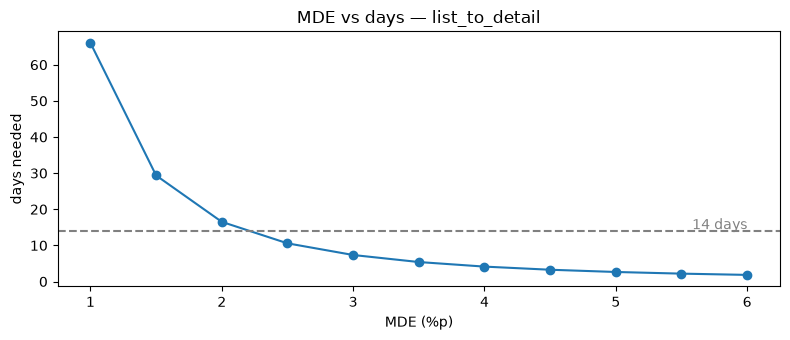

In [9]:
# [1.5-C] 필요한 기간
# 실험 전 데이터에서 대상 사용자의 하루 평균 '분모 세션 수'를 구하고, 그룹당으로 환산하세요.

num_col, den_col = METRICS[PRIMARY]
daily_denominator = target_pre.groupby("day")[den_col].sum().mean()
TRAFFIC_SHARE = 1.0
daily_per_group = daily_denominator * TRAFFIC_SHARE / 2

n_per_group = n_per_group_naive * design_effect
days_needed = n_per_group / daily_per_group
print(f"그룹당 필요한 분모 세션(디자인 효과 반영): {n_per_group:,.0f}")
print(f"그룹당 하루 분모 세션: {daily_per_group:,.0f} → 계산상 {days_needed:.1f}일")

# MDE를 바꾸면 기간이 어떻게 달라지는지
mdes = np.arange(0.01, 0.061, 0.005)
days = [NormalIndPower().solve_power(proportion_effectsize(p0 + m, p0), alpha=ALPHA, power=POWER) * design_effect / daily_per_group for m in mdes]
plt.figure(figsize=(8, 3.5))
plt.plot(mdes * 100, days, marker="o")
plt.axhline(14, ls="--", c="gray"); plt.text(mdes[-1] * 100, 14.5, "14 days", ha="right", color="gray")
plt.xlabel("MDE (%p)"); plt.ylabel("days needed"); plt.title(f"MDE vs days — {PRIMARY}")
plt.tight_layout(); plt.show()

### Q1.5 표본과 기간

1. A/A 테스트 결과 두 그룹의 차이는 유의했나요? 유의하지 않아야 정상인 이유는?
2. 사용자 단위 표준오차가 세션 독립 가정 표준오차보다 큰 이유를 "같은 사람의 세션"이라는 말을 써서 설명하세요.
3. 계산상 필요한 일수와 **최종으로 정한 실험 기간**은 각각 며칠인가요? 계산값보다 길게 잡았다면 그 이유는?
4. MDE를 어떤 근거로 정했나요? (통계가 아닌 **비즈니스 관점**의 근거를 포함)
5. (선택) `PRIMARY`를 `search_to_complete`로 바꿔 다시 계산해보세요. 기간이 어떻게 달라지나요? 이것이 1.3의 지표 역할 선택에 어떤 의미가 있나요?

**답변:**
1. A/A 테스트 결과 A그룹의 전환율은 47.96%, B그룹은 48.03%이고, p값은 0.9281로 0.05보다 크다.신뢰구간이 0을 포함하므로 두 그룹의 차이가 유의하지 않다.
2. 같은 사람의 세션은 구매 성향이나 평소 구매 습관 같은게 같기 때문에 서로 독립적이지 않다. 세션을 모두 독립으로 취급하면 실제보다 정보량을 많게 평가해서 표준오차를 과소평가한다.
3. 디자인 효과를 반영한 필요 표본은 그룹당 약 6935개의 목록 진입 세션이고, 그룹당 하루 평균 약 945개가 발생하므로 두 수를 나누면 약 7.3이다. 최종으로 정한 싫럼 기간은 주중, 주말 주기를 2번 포함하기 (=14주) 위해서이다.
4. MDE는 3%p로 정했고, 이는 기준 전환율 48.02%에서 51.02%로의 증가와 같다. 3%p는 목록 진입 1000건 당 상세 진입이 30건이 늘어나는 수준이고 , 그래프에서도 3%p는 약 7-8일 정도가 필요해 14일 내에서 탐지할 수 있다.

## 1.6 실험 기간 중간에 외부 변화가 생긴다면?

마케팅팀에서 연락이 왔습니다. **실험 8일차부터 promotion 채널 대규모 광고 캠페인이 시작**되어 promotion 유입이 크게 늘어납니다.

1. 이 캠페인은 A그룹과 B그룹에 **똑같이** 영향을 줍니다. 그래도 실험 결과 해석에 문제가 생길까요? 무작위 배정의 성질로 설명하세요.
2. 캠페인으로 새로 들어오는 사용자는 평소 promotion 사용자와 어떻게 다를까요? 어떤 지표의 수준이 8일차 전후로 달라질까요?
3. 이 상황에서 설계를 바꾸거나 분석 계획에 추가할 것이 있다면? (캠페인을 피해 실험을 미루거나 줄이는 선택지도 검토)

**답변:**
1. 동일하게 영향을 주고, 무작위 배정 등이 유지된다면 실험 결과 해석에 문제가 생기지 않을 것이다.
2. 캠페인으로 새로 들어오는 사용자는 평소 프로모션 사용자보다 혜택에 더 관심을 많이 가지고 있을 것이다. 목록 -> 상세 전환율과 검색당 매출의 수준 등도 달라질 수 있다.
3. 14일 실험을 유지한다.

## 1.7 사전 판정 규칙

결과를 보기 **전에** 아래 표를 채우세요. Part 2에서는 이 표대로 판정합니다.

| 상황 | 판정 |
|---|---|
| 데이터 품질(SRM) 검정 p < 0.001 | 보류 |
| Primary가 유의하게 개선 + 모든 Guardrail 유의한 악화 없음 | 배포 O |
| Primary가 유의하게 개선 + Guardrail 중 하나라도 유의하게 악화 | 배포 X |
| Primary 유의하지 않음 |  보류|
| (선택) 그 밖에 미리 정해두고 싶은 규칙 |  |

In [10]:
# [1.8] 최종 설계서 — 위에서 정한 값을 그대로 옮기세요. 이 셀이 Part 2의 실험을 결정합니다.

my_design = {
    "idea":           "A",      # "A" | "B" | "C"
    "target":         "promotion",      # "promotion" | "all"
    "unit":           "user",      # "user" | "session"
    "primary_metric": PRIMARY,
    "guardrails":     ["search_to_complete", "revenue_per_search"],      # 예: ["search_to_complete", "detail_to_room"]
    "secondary":      [],
    "alpha":          ALPHA,
    "power":          POWER,
    "mde_abs":        MDE,
    "traffic_share":  TRAFFIC_SHARE,
    "duration_days":  14,        # 1.5에서 정한 최종 기간 (3~42)
    "stopping":       "fixed",      # "fixed": 정한 기간까지 / "peek": 매일 확인하다 유의하면 중단
}
my_design

{'idea': 'A',
 'target': 'promotion',
 'unit': 'user',
 'primary_metric': 'list_to_detail',
 'guardrails': ['search_to_complete', 'revenue_per_search'],
 'secondary': [],
 'alpha': 0.05,
 'power': 0.8,
 'mde_abs': 0.03,
 'traffic_share': 1.0,
 'duration_days': 14,
 'stopping': 'fixed'}

---
# Part 2. 실행과 판정

여기서부터는 Part 1을 수정하지 마세요. 아래 셀을 실행하면 **여러분의 설계대로** 실험이 진행됩니다.

In [12]:
exp = run_experiment(my_design, SEED)
display(exp.head())

실험 기간: 2026-03-02 ~ 2026-03-15 (14일)
실험에 노출된 사용자: 11,743명 / 세션: 34,374개
참고: 실험 8일차(2026-03-09)부터 마케팅팀의 promotion 채널 대규모 광고 캠페인이 시작됐습니다.


,session_id,user_id,channel,device,user_type,day,session_start,group,search,list_view,detail_view,room_select,checkout,payment_complete,payment_method,amount,cancelled,net_amount
0,E00000000,200039,promotion,android,leisure,1,2026-03-02 10:18:41,A,1,1,0,0,0,0,None,0.0000,0,0.0000
1,E00000001,200070,promotion,android,leisure,1,2026-03-02 08:12:20,B,1,1,1,1,1,1,card,"204,400.0000",0,"204,400.0000"
2,E00000002,200072,promotion,android,business,1,2026-03-02 21:39:19,A,1,0,0,0,0,0,None,0.0000,0,0.0000
3,E00000003,200148,promotion,web,leisure,1,2026-03-02 12:05:43,B,1,1,0,0,0,0,None,0.0000,0,0.0000
4,E00000004,200148,promotion,web,leisure,1,2026-03-02 18:50:30,B,1,1,1,1,1,0,card,0.0000,0,0.0000


## 2.1 데이터 품질 — SRM 확인

결과 지표를 보기 전에 **배정 비율이 설계(50:50)대로인지** 먼저 확인합니다.

In [16]:
from scipy.stats import chisquare

# 주석 빈칸: 배정 단위가 사용자이므로, 그룹별 고유 사용자 수를 세어야 한다.
counts = exp.groupby("group")["user_id"].nunique()
print(counts)

total = counts.sum()
srm_p = chisquare(counts.values, f_exp=[total * 0.5, total * 0.5]).pvalue
print(f"SRM 검정 p-value: {srm_p:.2e}  →  {'SRM 의심! 결과 해석을 멈추세요' if srm_p < 0.001 else '통과'}")

# 어디서 어긋났는지 보기: 기기별 그룹 사용자 수
display(exp.groupby(["device", "group"])["user_id"].nunique().unstack())

group
A    5874
B    5869
Name: user_id, dtype: int64
SRM 검정 p-value: 9.63e-01  →  통과


group,A,B
device,,
android,2413,2428
ios,2213,2238
web,1248,1203


### Q2.1
1. SRM 검정 결과는? 통과하지 못했다면, 기기별 표에서 어디가 어긋났나요?
2. SRM이 있을 때 결과를 그대로 믿으면 안 되는 이유는? "어떤 사용자가 빠졌는가"의 관점에서 설명하세요.

**답변:** 
1. A그룹은 5874명, B그룹은 5869명이고, SRM 검정 결과 p-value가 9.63e-01이어서 0.001보다 커서 통과했다. 기기별 사용자 수도 큰 불균형이 관찰되지 않았다.
2. SRM이 있을 때 특정 기기나 행동 특성을 가진 사용자가 누락되었을 수도 있으니까 결과를 그대로 믿으면 안 된다.

## 2.2 지표 분석

`ratio_test(df, metric)`은 두 가지 표준오차를 함께 보여줍니다.
- `se_naive`, `p_naive`: 세션을 서로 독립인 관측으로 본 계산
- `se_delta`, `p_value`, `ci_low ~ ci_high`: 같은 사용자의 세션끼리 묶어서 계산 (**판정에는 이쪽을 사용**)

In [14]:
# [2.2-A] Primary + Guardrail + Secondary 결과표
metrics_to_check = [my_design["primary_metric"]] + my_design["guardrails"] + my_design["secondary"]

results = pd.DataFrame([ratio_test(exp,m) for m in metrics_to_check])
display(results)

,metric,A,B,diff,rel_diff,ci_low,ci_high,p_value,se_delta,se_naive,p_naive
0,list_to_detail,0.4340,0.4677,0.0338,0.0778,0.0196,0.0479,0.0000,0.0072,0.0056,0.0000
1,search_to_complete,0.1139,0.1229,0.0090,0.0794,0.0011,0.0170,0.0252,0.0040,0.0035,0.0094
2,revenue_per_search,"20,042.9570","21,215.6534","1,172.6965",0.0585,-319.2108,"2,664.6038",0.1234,761.1912,669.1671,0.0797


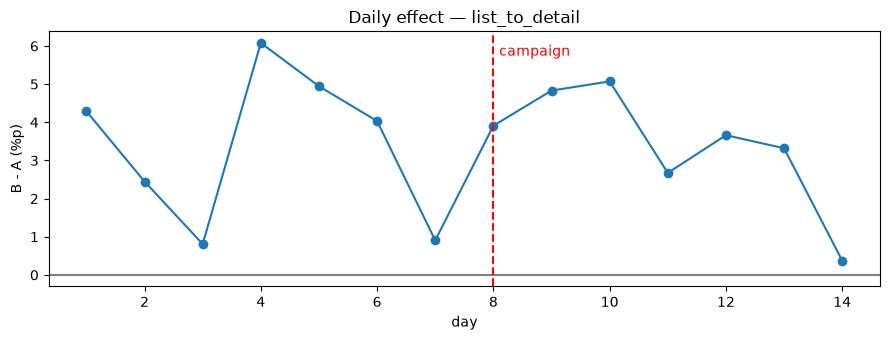

1~7일: diff=+0.0337, 95% CI [+0.0144, +0.0529]
8일~: diff=+0.0339, 95% CI [+0.0171, +0.0507]


In [ ]:
# [2.2-B] 일별 Primary 효과 — 신규성 효과와 8일차(캠페인 시작) 전후 확인
num_col, den_col = METRICS[my_design["primary_metric"]]
daily = exp.groupby(["day", "group"]).agg(num=(num_col, "sum"), den=(den_col, "sum")).reset_index()
daily["rate"] = daily["num"] / daily["den"]

# 주석 빈칸: pivot 후 B - A를 계산하면 그날 하루의 Primary 전환율 차이를 볼 수 있다.
daily_diff = daily.pivot(index="day", columns="group", values="rate")
daily_diff["diff"] = daily_diff["B"] - daily_diff["A"]

plt.figure(figsize=(9, 3.5))
plt.plot(daily_diff.index, daily_diff["diff"] * 100, marker="o")
plt.axhline(0, c="gray"); plt.axvline(8, ls="--", c="red"); plt.text(8.1, plt.ylim()[1] * 0.9, "campaign", color="red")
plt.xlabel("day"); plt.ylabel("B - A (%p)"); plt.title(f"Daily effect — {my_design['primary_metric']}")
plt.tight_layout(); plt.show()

# 전반부(1~7일) vs 후반부(8일~) 효과
for name, sub in [("1~7일", exp[exp["day"] <= 7]), ("8일~", exp[exp["day"] >= 8])]:
    r = ratio_test(sub, my_design["primary_metric"])
    print(f"{name}: diff={r['diff']:+.4f}, 95% CI [{r['ci_low']:+.4f}, {r['ci_high']:+.4f}]")

### Q2.2
1. Primary의 효과를 **점추정이 아니라 신뢰구간으로** 한 문장으로 말하세요. (예: "목록 → 상세 전환율이 ○%p에서 ○%p 사이로 올랐다")
2. `se_naive`와 `se_delta` 중 어느 쪽이 더 큰가요? naive로 판정했다면 어떤 위험이 있나요?
3. 일별 그래프에서 효과가 기간 내내 비슷한가요, 아니면 초반에 몰려 있나요? 어떤 의미인가요?
4. Guardrail 지표는 어떻게 나왔나요? "유의한 악화 없음"과 "변화 없음이 증명됨"은 같은 말인가요?
5. A그룹과 B그룹의 Primary 지표 **수준**이 8일차 전후로 어떻게 달라졌나요? 그런데도 A/B 비교가 유효한 이유는?

**답변:**
1. 목록 -> 상세 전환율이 약 1.96~4.79%p 높이는 것으로 추정된다. (95% 신뢰구간)
2. Primary의 `se_delta`는 0.0072로 `se_naive`인 0.0056보다 크다. Naive 방식은 같은 사용자의 반복 세션을 독립으로 취급해서 표준오차를 과소평가하므로 신뢰구간이 너무 좁아질 수 있다.
3. 일별 그래프에서 효과는 변동하지만 모든 날에서 양수이고, 초반에만 나타났다가 사라지는 형태를 보이지는 않는다. 
4. 검색 -> 결제완료 전환율은 약 0.9%p 증가했고 p-value=0.0252이기 때문에 유의하다. 검색당 매출은 약 1173원 증가했지만 신뢰구간이 -319.2108~2665.6038으로 0을 포함하기 때문에 유의하지 않다. (p-value=0.1234) 두 Guardrail 모두 유의한 학와는 없지만 이게 변화 가능성이 전혀 없다는 뜻과 같지는 않다.
5. 위 그래프는 B-A 차이만 보여주므로 A,B 각각의 수준이 어떻게 달라졌는지를 알 수는 없다.

## 2.3 판정

1.7의 사전 판정 규칙을 그대로 적용하세요.

- **해당하는 규칙 행:** Primary가 유의하게 개선 + 모든 Guardrail 유의한 악화 X
- **판정:** 배포
- **결정 메모 (3~5문장):** 목록 -> 상세 전환율이 약 1.96~4.79%p 높아지는 것으로 추정된다. 최종 결제 전환율도 유의하게 개선되었고 검색당 매출에서는 유의한 악화가 확인되지 않기 때문에 배포한다. 배포 후 매출과 가격 표시 정확도를 계속 모니터링해야 할ㄴ다.
- **다음 실험 아이디어 (1개):** 할인 가격과 함께 적용 조건을 목록에 잘 표시하면 가격만 표시할 때보다 검색 -> 결제완료 전환율이 높아지는지 검증한다.

---
# Part 3. 심화 과제 — 아래 중 1개 선택

같은 사용자 데이터로 **설계 한 가지만 바꿔** 다시 실험하고, 결과가 왜 달라졌는지 분석하세요.

| 선택 | 바꿀 것 | 생각해볼 질문 |
|---|---|---|
| **A. 기간과 중단 규칙** | `duration_days`를 7로, 또는 `stopping`을 `"peek"`으로 | 언제 멈췄나? 효과 크기가 어떻게 달라졌나? 왜? |
| **B. 대상 범위** | `target`을 반대로 | 효과 크기와 표준오차가 어떻게 달라졌나? 어느 쪽이 의사결정에 유리한가? |
| **C. 배정 단위** | `unit`을 반대로 | 효과 크기가 왜 달라졌나? 사용자 경험 측면의 문제는? |

### 심화 과제 작성
- 선택한 항목:
- 바꾼 설계 값:
- 원래 결과 vs 바뀐 결과 (핵심 숫자 2~3개):
- 왜 달라졌는가:
- 실무에서 이 교훈을 적용한다면:

In [ ]:
# [심화 과제 Skeleton]
alt_design = dict(my_design)
alt_design["__BLANK__"] = "__BLANK__"      # 바꿀 설계 하나

alt = run_experiment(alt_design, SEED)
alt_results = pd.DataFrame([ratio_test(alt, m) for m in metrics_to_check])
display(pd.concat({"원래 설계": results.set_index("metric"), "바꾼 설계": alt_results.set_index("metric")}, axis=1))

---
# Part 4. 회고

- 설계 단계에서 가장 고민했던 결정과 그 이유: B-A 차이에 대한 그래프 해석, 그래프 해석 방법을 고민하고 있어 ai의 도움을 받으려 했지만 나와 의견이 달라 고민이 되었다.
- 결과를 보고 "설계를 바꾸고 싶다"고 느낀 순간이 있었나요? 있었다면 무엇이었나요? 검색당 매출이 증가했지만 통계적으로 유의하지 않아서 기간을 연장하고 싶었다.
- 진단 결과를 실험으로 검증해보며 새로 알게 된 점 (다음 그로스 세션에서는 이런 진단을 직접 하는 법을 배웁니다): 특정 채널의 전환율이 낮다는 진단만으로는 원인이나 개선안의 효과를 확정할 수 없다는 점을 알게 되었다.
- 가장 어려웠던 부분: X

---
# Part 5. 제출 전 체크리스트

- [ ] Q0에서 실험이 필요한 처방과 바로 고쳐야 하는 처방을 구분했는가?
- [ ] 가설에 바꾸는 것, 행동 메커니즘, 지표와 방향이 모두 있는가?
- [ ] 모든 지표의 분자 / 분모 / Grain / Window를 명시했는가?
- [ ] 배정 단위와 분석 단위의 차이를 고려했는가? (A/A 테스트, 디자인 효과)
- [ ] MDE를 비즈니스 근거로 정했고, 기간을 계산값보다 짧지 않게 정했는가?
- [ ] 판정 규칙을 결과를 보기 전에 정했고, 결과를 본 뒤 Part 1을 수정하지 않았는가?
- [ ] SRM을 가장 먼저 확인했는가?
- [ ] 효과를 신뢰구간으로 말했는가?
- [ ] 기술블로그에 옮길 설계서, 그래프, 결정 메모를 정리했는가?
- [ ] 마지막 셀에 AI 활용 방법과 대화 내역을 붙였는가?

---
# Part 6. 생성형 AI 활용 방법 + 대화 내역 (필수)

AI를 사용했다면 아래를 작성하고, **대화 내역을 붙여넣으세요.** 사용하지 않았다면 "사용하지 않음"이라고 적어주세요.

1. 어느 문항에서, 어떤 목적으로 AI를 썼나요? Q1.5-2번, Q1.5-3번, Q2.2-5번
2. AI의 답 중 **본인 데이터로 확인해보니 틀렸거나 맞지 않았던 것**이 있었나요?
3. 이번 과제에서 AI에게 맡길 수 없었던, **사람이 직접 판단해야 했던 결정**은 무엇이었나요? Q2.2-5번 (AI는 답변을 해주었지만 내가 생각한 답변과 달랐음)

### 대화 내역
1. Q1.5번 - 2,3번

**2번은 “독립적이지 않아서, 실제 정보량이 세션 개수만큼 많지는 않다”로 연결하면 돼!**

같은 사람이 10번 방문했다고 해서 **서로 다른 10명이 방문한 것만큼 다양한 정보를 얻은 건 아니잖아.** 그런데 세션을 독립이라고 가정하면 이걸 독립적인 정보 10개로 계산해버려.

그러면 **정보가 실제보다 많다고 생각함 → 결과가 더 정확하다고 생각함 → 불확실성을 나타내는 표준오차를 너무 작게 계산함.**

따라서 같은 사람의 세션을 묶어서 계산하면 표준오차가 더 커지는 거야. 네 결과에서도 **0.0061 → 0.0078**로 커졌어.

**2번 복붙용**

같은 사람의 세션은 행동 성향을 공유하므로 서로 독립적이지 않다. 이를 독립으로 가정하면 실제보다 정보량을 많게 평가하여 표준오차를 과소평가한다. 따라서 같은 사용자의 반복 세션을 고려한 사용자 단위 표준오차가 더 크게 계산된다.

---

**3번은 “각 그룹에 필요한 세션을 모으는 데 며칠 걸리냐”를 계산한 거야.**

**① 처음에는 그룹당 4,359개가 필요하다고 계산함**

세션이 모두 독립적이라고 가정했을 때, **3%p의 차이를 탐지하려면 A·B 각각 목록 진입 세션 약 4,359개가 필요하다**는 뜻이야. 사용자 수가 아니라 **목록 진입 세션 수**야!

**② 반복 방문을 고려하니 더 많은 세션이 필요함**

아까 같은 사람의 세션은 정보가 일부 겹친다고 했지? 그걸 고려해서 필요한 표본 수를 늘려주는 거야.

\[
\text{그룹당 필요 세션}
=\text{독립 가정 필요 세션}\times\text{디자인 효과}
\]

\[
\approx 4,359\times1.59
\approx6,935\text{개}
\]

표시된 숫자는 반올림된 값이라 직접 곱하면 조금 다를 수 있어.

**③ 하루에 각 그룹에 약 945개씩 쌓임**

실험 전 데이터에서 promotion 사용자의 목록 진입 세션이 하루 평균 약 1,890개였어. 대상 전체를 실험에 넣고 A·B를 반반 나누니까,

\[
\text{그룹당 하루 세션}
=\frac{1,890}{2}
\approx945\text{개}
\]

**④ 필요한 양 ÷ 하루에 모이는 양 = 필요한 기간**

\[
\text{필요 기간}
=\frac{6,935}{945}
\approx7.3\text{일}
\]

즉, **계산상으로는 약 7.3일, 온전한 날짜로는 최소 8일 정도 모아야 한다**는 뜻이야.

**⑤ 그런데 실제 실험은 14일로 정함**

7.3일은 평균 트래픽을 기준으로 한 계산이야. 실제로는 요일별 방문량과 행동이 다를 수 있으니, **월~일을 두 번 포함하는 14일** 동안 운영해서 주중·주말을 균형 있게 관찰하고 표본도 여유 있게 확보하는 거야.

**3번 복붙용**

디자인 효과를 반영한 필요 표본은 그룹당 약 6,935개의 목록 진입 세션이다. 그룹당 하루 평균 약 945개가 발생하므로 계산상 필요한 기간은 약 7.3일이다. 최종 실험 기간은 주중·주말 주기를 두 번 포함하고 트래픽 변동에 대비하기 위해 14일로 정한다.


2. Q2.2번 - 5번
캠페인으로 구매 의도가 낮은 유입이 늘어나면서 A·B그룹 모두 목록→상세 전환율이 낮아질 수 있다. 다만 제시된 그래프는 B−A 차이이므로 각 그룹의 실제 하락 여부를 직접 보여주지는 않는다. 두 그룹 간 개선 효과는 캠페인 전 **3.37%p**, 이후 **3.39%p**로 비슷하게 유지되었다. 캠페인이 양쪽에 동일하게 적용되고 무작위 배정이 유지되므로, 같은 기간의 A/B 비교는 유효하다.